# Cannabis Consumption Trends in the United States
## 02 — Statistical Analysis

**Project:** Cannabis Consumption Trends  
**Author:** Greencloudz  
**Data Source:** Monitoring the Future — University of Michigan  
**Study Period:** 1975–2025  

---

### Research Objective

Quantify historical changes in cannabis-related consumption prevalence among U.S. students using descriptive statistical methods.

### Research Questions

1. How has cannabis prevalence changed year over year?
2. Which periods experienced the largest increases and decreases?
3. How do historical trends differ across educational grades?
4. Do different cannabis consumption indicators exhibit similar temporal patterns?

### Statistical Approach

The analysis will include:

- Year-over-year changes.
- Absolute and relative changes.
- Historical trend assessment.
- Descriptive variability.
- Exploratory correlation analysis, where methodologically appropriate.

### Methodological Limitations

The dataset contains aggregated survey prevalence estimates rather than individual-level observations.

Statistical significance testing requires additional information about survey design and sampling uncertainty.

Correlation does not establish causation.

---

## 1. Environment Setup and Data Loading

This section imports the required libraries and loads the processed dataset.

The dataset was previously cleaned and validated during the exploratory data analysis.

All statistical calculations will use the original reported prevalence estimates without interpolation or imputation.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Define dataset location
DATA_PATH = Path("../data/processed/cannabis_prevalence_clean.csv")

# Load processed dataset
df = pd.read_csv(DATA_PATH)

# Validate required columns
required_columns = {"drug", "time", "grade", "estimate", "year"}

assert required_columns.issubset(df.columns), (
    "Required dataset columns are missing."
)

# Validate dataset integrity
assert df["estimate"].between(0, 100).all(), (
    "Invalid prevalence estimates detected."
)

assert not df.duplicated(
    subset=["drug", "time", "grade", "year"]
).any(), "Duplicate observations detected."

print("STATISTICAL ANALYSIS | DATASET VALIDATION")
print("-" * 50)
print(f"Total observations: {len(df)}")
print(f"Dataset dimensions: {df.shape}")
print(f"Study period: {df['year'].min()}–{df['year'].max()}")
print(f"Consumption categories: {df['drug'].nunique()}")
print(f"Educational grades: {df['grade'].nunique()}")

display(df.head())

STATISTICAL ANALYSIS | DATASET VALIDATION
--------------------------------------------------
Total observations: 660
Dataset dimensions: (660, 5)
Study period: 1975–2025
Consumption categories: 5
Educational grades: 3


,drug,time,grade,estimate,year
0,CBD,12 Month,10th Grade,11.8,2023
1,CBD,12 Month,10th Grade,8.3,2024
2,CBD,12 Month,12th Grade,15.8,2023
3,CBD,12 Month,12th Grade,13.3,2024
4,CBD,12 Month,8th Grade,5.0,2023


## 2. Year-over-Year Prevalence Analysis

### 2.1 Annual Changes in Cannabis Use

Year-over-Year (YoY) analysis measures changes in prevalence between consecutive survey years.

**Research Question:**

Which years experienced the largest increases and decreases in cannabis use prevalence?

**Metrics:**

- **Absolute YoY Change (pp):** Difference in prevalence between consecutive years.
- **Relative YoY Change (%):** Percentage change relative to the previous year's prevalence.

**Formulas:**

Absolute YoY Change = Current Prevalence − Previous Prevalence

Relative YoY Change = (Absolute YoY Change / Previous Prevalence) × 100

**Methodological Considerations:**

- Calculations are performed separately for each product category, reporting interval, and educational grade.
- Changes are calculated only between consecutive survey years.
- Missing historical observations are not interpolated.
- YoY changes describe differences between survey estimates, not necessarily statistically significant changes.

In [2]:
import pandas as pd
from pathlib import Path

# Load the processed dataset
DATA_PATH = Path("../data/processed/cannabis_prevalence_clean.csv")
df = pd.read_csv(DATA_PATH)

# Define historical series identifiers
GROUP_COLUMNS = ["drug", "time", "grade"]

# Sort observations chronologically
yoy_data = df.sort_values(
    GROUP_COLUMNS + ["year"]
).copy()

# Calculate previous-year values
yoy_data["previous_year"] = (
    yoy_data.groupby(GROUP_COLUMNS)["year"].shift(1)
)

yoy_data["previous_prevalence"] = (
    yoy_data.groupby(GROUP_COLUMNS)["estimate"].shift(1)
)

# Identify consecutive survey years
consecutive_year = (
    yoy_data["year"] - yoy_data["previous_year"] == 1
)

# Calculate absolute annual change
yoy_data["yoy_change_pp"] = (
    yoy_data["estimate"] - yoy_data["previous_prevalence"]
).where(consecutive_year)

# Calculate relative annual change
yoy_data["yoy_change_pct"] = (
    yoy_data["yoy_change_pp"]
    / yoy_data["previous_prevalence"].replace(0, float("nan"))
) * 100

# Display calculation summary
print("YEAR-OVER-YEAR ANALYSIS")
print("-" * 50)
print(f"Total observations: {len(yoy_data)}")
print(f"Valid YoY comparisons: {yoy_data['yoy_change_pp'].notna().sum()}")
print(f"Unavailable YoY comparisons: {yoy_data['yoy_change_pp'].isna().sum()}")

display(
    yoy_data[
        [
            "drug",
            "time",
            "grade",
            "year",
            "estimate",
            "previous_prevalence",
            "yoy_change_pp",
            "yoy_change_pct"
        ]
    ].head(10).round(2)
)

YEAR-OVER-YEAR ANALYSIS
--------------------------------------------------
Total observations: 660
Valid YoY comparisons: 620
Unavailable YoY comparisons: 40


,drug,time,grade,year,estimate,previous_prevalence,yoy_change_pp,yoy_change_pct
0,CBD,12 Month,10th Grade,2023,11.8,NaN,NaN,NaN
1,CBD,12 Month,10th Grade,2024,8.3,11.8,-3.5,-29.66
2,CBD,12 Month,12th Grade,2023,15.8,NaN,NaN,NaN
3,CBD,12 Month,12th Grade,2024,13.3,15.8,-2.5,-15.82
4,CBD,12 Month,8th Grade,2023,5.0,NaN,NaN,NaN
5,CBD,12 Month,8th Grade,2024,3.3,5.0,-1.7,-34.00
6,Cannabis,12 Month,10th Grade,1991,16.5,NaN,NaN,NaN
7,Cannabis,12 Month,10th Grade,1992,15.2,16.5,-1.3,-7.88
8,Cannabis,12 Month,10th Grade,1993,19.2,15.2,4.0,26.32
9,Cannabis,12 Month,10th Grade,1994,25.2,19.2,6.0,31.25


### 2.2 Largest Annual Increases and Decreases

This section identifies the largest year-over-year changes in cannabis use prevalence.

**Research Objectives:**

- Identify the largest annual increases in prevalence.
- Identify the largest annual decreases in prevalence.
- Compare the magnitude of historical changes.
- Examine whether extreme fluctuations occurred during similar periods.

**Primary Metric:** Absolute year-over-year change (percentage points).

**Methodological Considerations:**

Absolute changes are prioritized over relative changes because percentages calculated from very small baseline values may exaggerate the apparent magnitude of fluctuations.

Changes between nonconsecutive survey years are excluded.

The analysis identifies historical extremes in survey estimates, not necessarily statistically significant changes.

In [4]:
import pandas as pd
from pathlib import Path

# Load the processed dataset
df = pd.read_csv(
    "../data/processed/cannabis_prevalence_clean.csv"
)

# Define historical series
group_columns = ["drug", "time", "grade"]

# Sort observations
yoy_data = df.sort_values(
    group_columns + ["year"]
).copy()

# Calculate previous observations
yoy_data["previous_year"] = (
    yoy_data.groupby(group_columns)["year"].shift(1)
)

yoy_data["previous_prevalence"] = (
    yoy_data.groupby(group_columns)["estimate"].shift(1)
)

# Identify consecutive years
valid_comparison = (
    yoy_data["year"] - yoy_data["previous_year"] == 1
)

# Calculate annual changes
yoy_data["yoy_change_pp"] = (
    yoy_data["estimate"] - yoy_data["previous_prevalence"]
).where(valid_comparison)

# Select valid comparisons
valid_yoy = yoy_data.dropna(
    subset=["yoy_change_pp"]
).copy()

# Identify the largest increases
largest_increases = valid_yoy.nlargest(
    10, "yoy_change_pp"
)

# Identify the largest decreases
largest_decreases = valid_yoy.nsmallest(
    10, "yoy_change_pp"
)

# Define output columns
output_columns = [
    "drug",
    "time",
    "grade",
    "year",
    "previous_prevalence",
    "estimate",
    "yoy_change_pp"
]

print("TOP 10 LARGEST ANNUAL INCREASES")
display(largest_increases[output_columns].round(2))

print("\nTOP 10 LARGEST ANNUAL DECREASES")
display(largest_decreases[output_columns].round(2))

TOP 10 LARGEST ANNUAL INCREASES


,drug,time,grade,year,previous_prevalence,estimate,yoy_change_pp
599,Vaping Cannabis,Lifetime,12th Grade,2019,15.6,23.7,8.1
527,Vaping Cannabis,12 Month,12th Grade,2019,13.1,20.8,7.7
590,Vaping Cannabis,Lifetime,10th Grade,2019,14.2,21.8,7.6
518,Vaping Cannabis,12 Month,10th Grade,2019,12.4,19.4,7.0
554,Vaping Cannabis,30 Day,12th Grade,2019,7.5,14.0,6.5
9,Cannabis,12 Month,10th Grade,1994,19.2,25.2,6.0
372,Cannabis,Lifetime,10th Grade,1994,24.4,30.4,6.0
374,Cannabis,Lifetime,10th Grade,1996,34.1,39.8,5.7
545,Vaping Cannabis,30 Day,10th Grade,2019,7.0,12.6,5.6
405,Cannabis,Lifetime,12th Grade,1976,47.3,52.8,5.5



TOP 10 LARGEST ANNUAL DECREASES


,drug,time,grade,year,previous_prevalence,estimate,yoy_change_pp
399,Cannabis,Lifetime,10th Grade,2021,33.3,22.0,-11.3
36,Cannabis,12 Month,10th Grade,2021,28.0,17.3,-10.7
520,Vaping Cannabis,12 Month,10th Grade,2021,19.1,12.4,-6.7
157,Cannabis,30 Day,10th Grade,2021,16.6,10.1,-6.5
592,Vaping Cannabis,Lifetime,10th Grade,2021,22.7,16.5,-6.2
450,Cannabis,Lifetime,12th Grade,2021,43.7,38.6,-5.1
87,Cannabis,12 Month,12th Grade,2021,35.2,30.5,-4.7
485,Cannabis,Lifetime,8th Grade,2021,14.8,10.2,-4.6
122,Cannabis,12 Month,8th Grade,2021,11.4,7.1,-4.3
421,Cannabis,Lifetime,12th Grade,1992,36.7,32.6,-4.1


### 2.3 Year-over-Year Analysis: Key Findings

**Finding 1 — Rapid growth in cannabis vaping during 2019**

Several of the largest annual prevalence increases occurred in cannabis vaping indicators during 2019.

Notable changes included:

- 12th Grade, Lifetime: +8.1 percentage points.
- 12th Grade, Past-Year: +7.7 percentage points.
- 10th Grade, Lifetime: +7.6 percentage points.
- 10th Grade, Past-Year: +7.0 percentage points.

These observations indicate substantial increases in reported cannabis vaping prevalence between 2018 and 2019.

**Finding 2 — Sharp prevalence declines in 2021**

Several of the largest annual declines occurred in 2021.

The most pronounced decreases included:

- 10th Grade, Cannabis Lifetime: −11.3 percentage points.
- 10th Grade, Cannabis Past-Year: −10.7 percentage points.
- 10th Grade, Vaping Cannabis Past-Year: −6.7 percentage points.
- 10th Grade, Vaping Cannabis Past-Month: −6.5 percentage points.

**Finding 3 — Historical fluctuations in general cannabis use**

Large annual changes were also observed during earlier decades.

For example:

- 10th Grade, Cannabis Past-Year: +6.0 percentage points in 1994.
- 10th Grade, Cannabis Lifetime: +6.0 percentage points in 1994.
- 12th Grade, Cannabis Lifetime: +5.5 percentage points in 1976.

These findings demonstrate that substantial annual fluctuations are not exclusive to recent periods.

**Interpretation**

The largest observed annual increases were concentrated primarily in cannabis vaping indicators during 2019, while several of the largest declines occurred in 2021.

The timing of the 2021 decreases coincides with the COVID-19 pandemic, but this descriptive analysis cannot establish whether the changes were caused by the pandemic.

**Methodological Limitations**

- Rankings are based on absolute percentage-point changes.
- Differences between survey estimates have not been tested for statistical significance.
- Survey methodology and administration conditions may influence historical comparisons.
- The analysis does not establish causal relationships.

## 3. Statistical Variability Analysis

### 3.1 Historical Prevalence Variability

This section examines the variability of cannabis-related prevalence estimates across educational grades and product categories.

**Research Question:**

Which cannabis-related categories experienced the greatest fluctuations in past-year prevalence between 2021 and 2025?

**Statistical Metrics:**

- **Mean:** Average annual prevalence estimate.
- **Standard Deviation:** Dispersion of annual prevalence estimates around their mean.
- **Minimum:** Lowest recorded prevalence.
- **Maximum:** Highest recorded prevalence.
- **Range:** Difference between maximum and minimum prevalence.

**Comparison Parameters:**

- Study period: 2021–2025.
- Reporting interval: Past 12 months.
- Educational grades: 8th, 10th, and 12th.
- Product categories: Cannabis, Vaping Cannabis, and Vaping Flavored Cannabis.

**Methodological Considerations:**

All comparisons use the same five-year observation period.

Standard deviation measures the variability of annual prevalence estimates, not individual consumption behavior or survey sampling uncertainty.

Because prevalence levels differ across categories, absolute variability should be interpreted alongside the mean prevalence.

Five annual observations provide only a limited representation of historical variability.

In [5]:
import pandas as pd
from pathlib import Path

# Load the processed dataset
DATA_PATH = Path("../data/processed/cannabis_prevalence_clean.csv")

df = pd.read_csv(DATA_PATH)

# Define comparison parameters
START_YEAR = 2021
END_YEAR = 2025

CATEGORIES = [
    "Cannabis",
    "Vaping Cannabis",
    "Vaping Flavored Cannabis"
]

GRADES = [
    "8th Grade",
    "10th Grade",
    "12th Grade"
]

# Filter comparable observations
variability_data = df[
    (df["drug"].isin(CATEGORIES))
    & (df["time"] == "12 Month")
    & (df["grade"].isin(GRADES))
    & (df["year"].between(START_YEAR, END_YEAR))
].copy()

# Calculate descriptive variability statistics
variability_summary = (
    variability_data
    .groupby(["drug", "grade"])["estimate"]
    .agg(
        observations="count",
        mean="mean",
        standard_deviation="std",
        minimum="min",
        maximum="max"
    )
    .reset_index()
)

# Calculate prevalence range
variability_summary["range_pp"] = (
    variability_summary["maximum"]
    - variability_summary["minimum"]
)

# Calculate coefficient of variation
variability_summary["cv_pct"] = (
    variability_summary["standard_deviation"]
    / variability_summary["mean"].replace(0, float("nan"))
) * 100

# Validate observation coverage
assert (variability_summary["observations"] == 5).all(), (
    "Incomplete historical series detected."
)

# Organize results
variability_summary["drug"] = pd.Categorical(
    variability_summary["drug"],
    categories=CATEGORIES,
    ordered=True
)

variability_summary["grade"] = pd.Categorical(
    variability_summary["grade"],
    categories=GRADES,
    ordered=True
)

variability_summary = variability_summary.sort_values(
    ["drug", "grade"]
).reset_index(drop=True)

print("PREVALENCE VARIABILITY ASSESSMENT | 2021–2025")
print("-" * 55)

display(variability_summary.round(2))

PREVALENCE VARIABILITY ASSESSMENT | 2021–2025
-------------------------------------------------------


,drug,grade,observations,mean,standard_deviation,minimum,maximum,range_pp,cv_pct
0,Cannabis,8th Grade,5,8.08,0.76,7.1,9.1,2.0,9.44
1,Cannabis,10th Grade,5,17.22,1.57,15.6,19.5,3.9,9.14
2,Cannabis,12th Grade,5,28.34,2.45,25.7,30.7,5.0,8.66
3,Vaping Cannabis,8th Grade,5,5.50,0.80,4.7,6.5,1.8,14.49
4,Vaping Cannabis,10th Grade,5,12.54,1.66,10.6,15.0,4.4,13.24
5,Vaping Cannabis,12th Grade,5,18.42,1.78,16.0,20.6,4.6,9.67
6,Vaping Flavored Cannabis,8th Grade,5,3.30,1.06,2.2,4.9,2.7,32.00
7,Vaping Flavored Cannabis,10th Grade,5,6.16,0.71,5.2,6.9,1.7,11.51
8,Vaping Flavored Cannabis,12th Grade,5,8.52,1.16,6.9,9.8,2.9,13.67


### 3.2 Statistical Variability: Key Findings

**Finding 1 — Highest absolute variability**

General cannabis use among 12th-grade students exhibited the highest standard deviation (2.45 percentage points) and the widest prevalence range (5.0 percentage points).

Annual prevalence estimates ranged from 25.7% to 30.7% between 2021 and 2025.

**Finding 2 — Highest relative variability**

Flavored cannabis vaping among 8th-grade students recorded the highest coefficient of variation (32.00%).

Its mean prevalence was 3.30%, with a standard deviation of 1.06 percentage points.

This indicates relatively large fluctuations compared with its average prevalence level.

**Finding 3 — Differences between absolute and relative variability**

General cannabis use among 12th-grade students had the highest absolute standard deviation but the lowest coefficient of variation (8.66%).

This demonstrates why absolute and relative variability should be interpreted separately.

**Finding 4 — Differences across product categories**

The results show that variability differs across cannabis-related product categories and educational grades.

However, higher variability does not necessarily indicate an increasing or decreasing prevalence trend.

**Interpretation**

The analysis demonstrates that prevalence fluctuations must be evaluated in relation to the underlying prevalence level.

Absolute variability is useful for understanding the magnitude of changes in percentage points, while relative variability helps contextualize fluctuations across series with different average prevalence estimates.

**Methodological Limitations**

- Each series contains only five annual observations.
- Standard deviation describes variation across annual survey estimates, not individual consumption behavior.
- The coefficient of variation can be sensitive to low mean prevalence values.
- Observed variability includes potential survey estimation uncertainty.
- Differences in variability have not been tested for statistical significance.

## 4. Linear Trend Analysis

### 4.1 Estimating Historical Prevalence Trends

This section uses simple linear regression to estimate the direction and magnitude of historical cannabis prevalence trends.

**Research Question:**

Which cannabis-related categories exhibit increasing or decreasing prevalence trends between 2021 and 2025?

**Statistical Metrics:**

- **Slope (pp/year):** Estimated average annual change in prevalence.
- **R² (Coefficient of Determination):** Proportion of observed variation explained by the fitted linear trend.
- **Absolute Change (pp):** Difference between 2021 and 2025 prevalence.

**Interpretation:**

- Positive slope: Increasing fitted trend.
- Negative slope: Decreasing fitted trend.
- Slope near zero: Relatively stable fitted trend.
- R² near 1: The fitted line closely describes the observed annual estimates.
- R² near 0: The fitted line explains little of the observed variation.

**Methodological Considerations:**

Each regression uses only five annual observations.

The analysis is descriptive. Conventional regression significance tests are not used because the data consist of aggregated survey estimates with unknown sampling uncertainty.

Linear trends do not establish causality and should not be interpreted as forecasts.

In [6]:
import pandas as pd
import numpy as np
from pathlib import Path

# Load the processed dataset
DATA_PATH = Path("../data/processed/cannabis_prevalence_clean.csv")
df = pd.read_csv(DATA_PATH)

# Define comparison parameters
START_YEAR = 2021
END_YEAR = 2025

CATEGORIES = [
    "Cannabis",
    "Vaping Cannabis",
    "Vaping Flavored Cannabis"
]

GRADES = [
    "8th Grade",
    "10th Grade",
    "12th Grade"
]

# Filter comparable observations
trend_data = df[
    (df["drug"].isin(CATEGORIES))
    & (df["time"] == "12 Month")
    & (df["grade"].isin(GRADES))
    & (df["year"].between(START_YEAR, END_YEAR))
].copy()

# Calculate linear trend metrics
results = []

for (category, grade), group in trend_data.groupby(["drug", "grade"]):

    group = group.sort_values("year")

    # Validate annual coverage
    assert group["year"].tolist() == list(
        range(START_YEAR, END_YEAR + 1)
    ), "Incomplete annual series detected."

    x = group["year"].to_numpy(dtype=float)
    y = group["estimate"].to_numpy(dtype=float)

    # Center the year variable for numerical stability
    x_centered = x - START_YEAR

    # Fit a descriptive linear regression
    slope, intercept = np.polyfit(x_centered, y, 1)

    # Calculate fitted values
    predicted = slope * x_centered + intercept

    # Calculate coefficient of determination
    ss_residual = np.sum((y - predicted) ** 2)
    ss_total = np.sum((y - y.mean()) ** 2)

    r_squared = (
        1 - ss_residual / ss_total
        if ss_total > 0 else np.nan
    )

    # Calculate observed endpoint change
    absolute_change = y[-1] - y[0]

    results.append({
        "Category": category,
        "Grade": grade,
        "Slope (pp/year)": slope,
        "R²": r_squared,
        "Absolute Change (pp)": absolute_change
    })

# Create results table
trend_summary = pd.DataFrame(results)

# Organize categories and grades
trend_summary["Category"] = pd.Categorical(
    trend_summary["Category"],
    categories=CATEGORIES,
    ordered=True
)

trend_summary["Grade"] = pd.Categorical(
    trend_summary["Grade"],
    categories=GRADES,
    ordered=True
)

trend_summary = trend_summary.sort_values(
    ["Category", "Grade"]
).reset_index(drop=True)

print("LINEAR TREND ANALYSIS | 2021–2025")
print("-" * 50)

display(trend_summary.round(3))

LINEAR TREND ANALYSIS | 2021–2025
--------------------------------------------------


,Category,Grade,Slope (pp/year),R²,Absolute Change (pp)
0,Cannabis,8th Grade,0.18,0.139,0.5
1,Cannabis,10th Grade,-0.70,0.495,-1.7
2,Cannabis,12th Grade,-1.45,0.873,-4.8
3,Vaping Cannabis,8th Grade,-0.04,0.006,0.0
4,Vaping Cannabis,10th Grade,-0.70,0.444,-1.8
5,Vaping Cannabis,12th Grade,-0.76,0.455,-2.3
6,Vaping Flavored Cannabis,8th Grade,0.14,0.044,0.4
7,Vaping Flavored Cannabis,10th Grade,0.05,0.012,0.6
8,Vaping Flavored Cannabis,12th Grade,0.39,0.280,1.3


### 4.2 Linear Trend Analysis: Key Findings

**Finding 1 — Strongest downward fitted trend**

General cannabis use among 12th-grade students recorded the steepest negative slope (−1.45 percentage points per year).

The linear model achieved an R² of 0.873, indicating a relatively strong fit to the five observed annual prevalence estimates.

**Finding 2 — Cannabis vaping trends**

Cannabis vaping exhibited negative fitted slopes across all three educational grades.

The largest declines were observed among:

- 12th Grade: −0.76 pp/year.
- 10th Grade: −0.70 pp/year.

However, the corresponding R² values indicate only moderate linear fit.

**Finding 3 — Flavored cannabis vaping**

Flavored cannabis vaping exhibited positive fitted slopes across all grades.

The largest positive slope occurred among 12th-grade students (+0.39 pp/year).

Nevertheless, low R² values suggest that linear trends explain relatively little of the observed annual variation.

**Finding 4 — Linear trends versus observed changes**

Regression slopes and endpoint changes describe different properties of a time series.

A positive endpoint change does not necessarily imply a consistently increasing historical trajectory.

**Interpretation**

The strongest descriptive linear decline was observed in general cannabis use among 12th-grade students.

Other categories exhibited weaker linear patterns, indicating that their annual prevalence estimates may be better described by nonlinear fluctuations.

**Limitations**

- Each regression contains only five annual observations.
- R² measures goodness of fit, not causality.
- Survey sampling uncertainty is not incorporated into the regression.
- No design-based statistical significance tests were performed.
- Fitted trends should not be extrapolated beyond the observation period.

### 4.3 Linear Regression Visualization

This visualization compares observed past-year cannabis prevalence estimates with fitted linear regression trends between 2021 and 2025.

**Research Objectives:**

- Visualize the direction of historical prevalence trends.
- Compare observed values with fitted regression estimates.
- Examine differences in linear model fit across product categories.
- Identify patterns that may not be adequately represented by linear trends.

**Visualization Design:**

- Three panels, one for each educational grade.
- Three cannabis-related product categories per panel.
- Solid lines represent observed prevalence estimates.
- Dashed lines represent fitted linear regression trends.
- Regression slopes and R² values are reported separately.

**Methodological Considerations:**

Each regression is based on five annual observations.

Fitted lines describe historical patterns rather than predictions.

A high R² indicates stronger agreement between observed values and the fitted linear model, but does not establish causality or statistical significance.

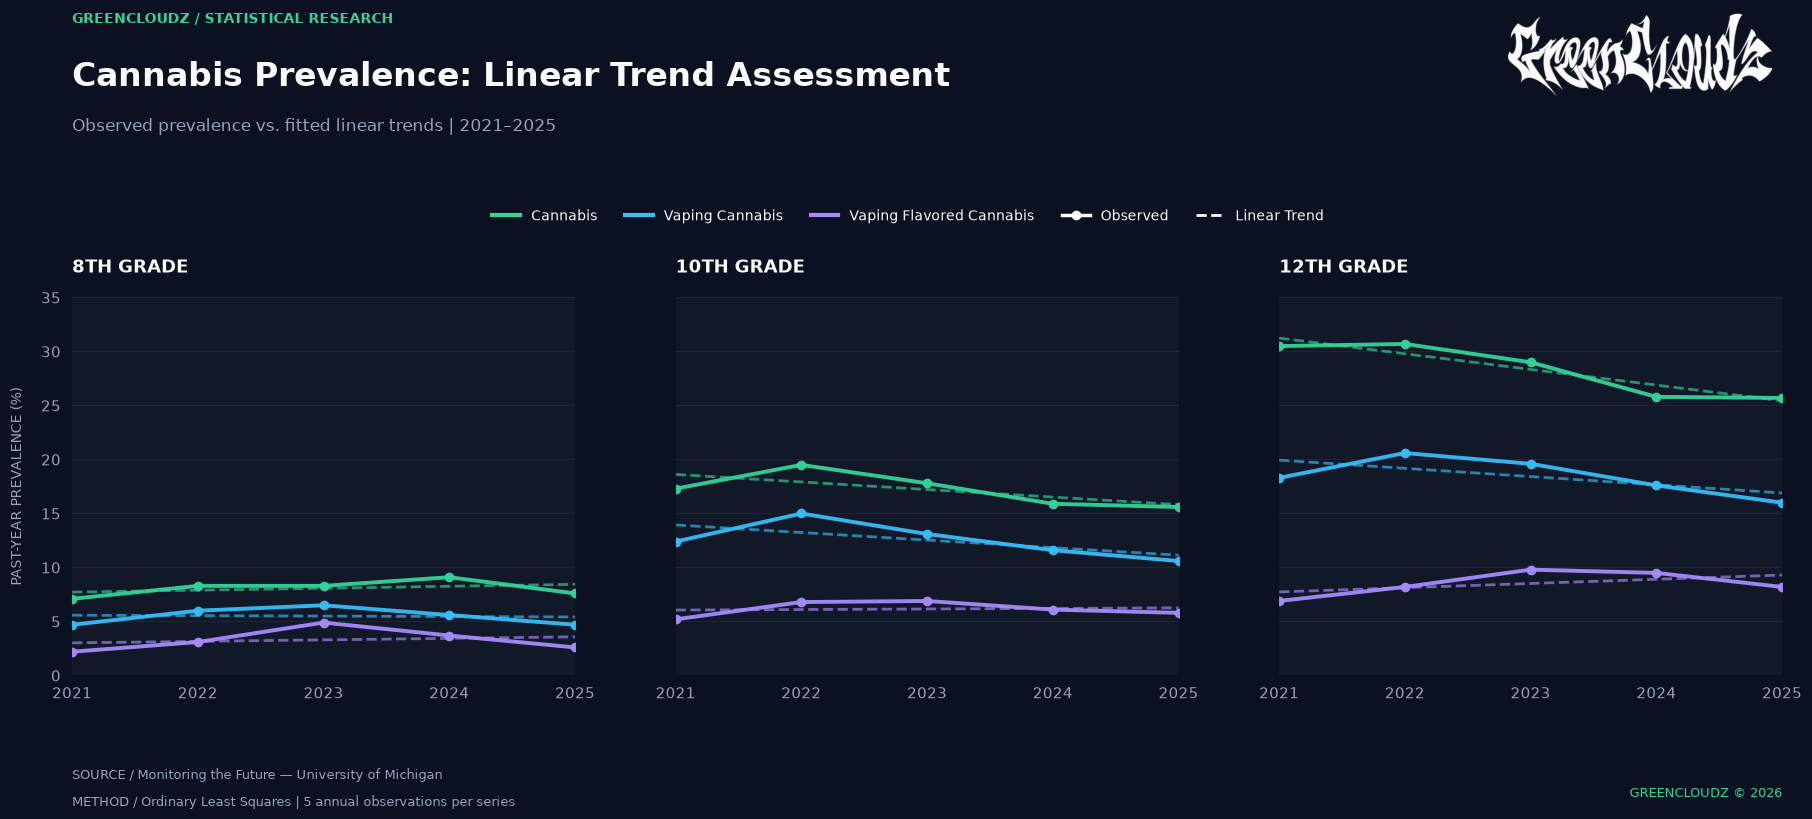

,Category,Grade,Slope (pp/year),R²
0,Cannabis,8th Grade,0.18,0.139
1,Vaping Cannabis,8th Grade,-0.04,0.006
2,Vaping Flavored Cannabis,8th Grade,0.14,0.044
3,Cannabis,10th Grade,-0.70,0.495
4,Vaping Cannabis,10th Grade,-0.70,0.444
5,Vaping Flavored Cannabis,10th Grade,0.05,0.012
6,Cannabis,12th Grade,-1.45,0.873
7,Vaping Cannabis,12th Grade,-0.76,0.455
8,Vaping Flavored Cannabis,12th Grade,0.39,0.280


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

from pathlib import Path
from matplotlib.lines import Line2D

# --------------------------------------------------
# GREENCLOUDZ | VISUAL IDENTITY
# --------------------------------------------------

COLORS = {
    "background": "#0B1120",
    "panel": "#111827",
    "text": "#F8FAFC",
    "muted": "#94A3B8",
    "grid": "#334155",
    "accent": "#34D399"
}

PRODUCT_COLORS = {
    "Cannabis": "#34D399",
    "Vaping Cannabis": "#38BDF8",
    "Vaping Flavored Cannabis": "#A78BFA"
}

# Configure typography
available_fonts = {font.name for font in fm.fontManager.ttflist}

font_family = next(
    (
        font for font in [
            "Montserrat",
            "Aptos",
            "DejaVu Sans"
        ]
        if font in available_fonts
    ),
    "DejaVu Sans"
)

plt.rcParams.update({
    "font.family": font_family,
    "font.size": 11,
    "text.color": COLORS["text"],
    "axes.labelcolor": COLORS["muted"],
    "xtick.color": COLORS["muted"],
    "ytick.color": COLORS["muted"]
})

# --------------------------------------------------
# DATA PREPARATION
# --------------------------------------------------

DATA_PATH = Path(
    "../data/processed/cannabis_prevalence_clean.csv"
)

df = pd.read_csv(DATA_PATH)

CATEGORIES = [
    "Cannabis",
    "Vaping Cannabis",
    "Vaping Flavored Cannabis"
]

GRADES = [
    "8th Grade",
    "10th Grade",
    "12th Grade"
]

START_YEAR = 2021
END_YEAR = 2025

trend_data = df[
    (df["drug"].isin(CATEGORIES))
    & (df["time"] == "12 Month")
    & (df["grade"].isin(GRADES))
    & (df["year"].between(START_YEAR, END_YEAR))
].copy()

# Validate data completeness
expected_observations = len(CATEGORIES) * len(GRADES) * 5

assert len(trend_data) == expected_observations, (
    "Unexpected number of observations."
)

assert not trend_data.duplicated(
    subset=["drug", "grade", "year"]
).any(), "Duplicate observations detected."

assert not trend_data["estimate"].isna().any(), (
    "Missing prevalence estimates detected."
)

# --------------------------------------------------
# FIGURE CONFIGURATION
# --------------------------------------------------

fig, axes = plt.subplots(
    1, 3,
    figsize=(19, 9),
    sharey=True,
    facecolor=COLORS["background"]
)

fig.subplots_adjust(
    left=0.06,
    right=0.96,
    top=0.64,
    bottom=0.22,
    wspace=0.20
)

# --------------------------------------------------
# HEADER
# --------------------------------------------------

fig.text(
    0.06, 0.945,
    "GREENCLOUDZ / STATISTICAL RESEARCH",
    fontsize=10,
    fontweight="bold",
    color=COLORS["accent"]
)

fig.text(
    0.06, 0.875,
    "Cannabis Prevalence: Linear Trend Assessment",
    fontsize=24,
    fontweight="bold",
    color=COLORS["text"]
)

fig.text(
    0.06, 0.825,
    "Observed prevalence vs. fitted linear trends | 2021–2025",
    fontsize=12,
    color=COLORS["muted"]
)

# --------------------------------------------------
# REGRESSION VISUALIZATION
# --------------------------------------------------

regression_results = []

for ax, grade in zip(axes, GRADES):

    ax.set_facecolor(COLORS["panel"])

    for category in CATEGORIES:

        series = trend_data[
            (trend_data["grade"] == grade)
            & (trend_data["drug"] == category)
        ].sort_values("year")

        # Validate complete annual series
        assert series["year"].tolist() == list(
            range(START_YEAR, END_YEAR + 1)
        ), "Incomplete annual series detected."

        x = series["year"].to_numpy(dtype=float)
        y = series["estimate"].to_numpy(dtype=float)

        # Center time values
        x_centered = x - START_YEAR

        # Fit linear regression
        slope, intercept = np.polyfit(
            x_centered,
            y,
            1
        )

        predicted = slope * x_centered + intercept

        # Calculate R-squared
        ss_residual = np.sum((y - predicted) ** 2)
        ss_total = np.sum((y - y.mean()) ** 2)

        r_squared = (
            1 - ss_residual / ss_total
            if ss_total > 0 else np.nan
        )

        regression_results.append({
            "Category": category,
            "Grade": grade,
            "Slope (pp/year)": slope,
            "R²": r_squared
        })

        # Plot observed prevalence
        ax.plot(
            x,
            y,
            color=PRODUCT_COLORS[category],
            linewidth=2.8,
            marker="o",
            markersize=6,
            alpha=0.95,
            zorder=3
        )

        # Plot fitted linear trend
        ax.plot(
            x,
            predicted,
            color=PRODUCT_COLORS[category],
            linewidth=2,
            linestyle="--",
            alpha=0.65,
            zorder=2
        )

    # Configure panel title
    ax.set_title(
        grade.upper(),
        loc="left",
        fontsize=13,
        fontweight="bold",
        color=COLORS["text"],
        pad=18
    )

    # Configure axes
    ax.set_xlim(2021, 2025)
    ax.set_xticks(range(2021, 2026))

    ax.set_ylim(0, 35)
    ax.set_yticks(range(0, 36, 5))

    ax.grid(
        axis="y",
        color=COLORS["grid"],
        alpha=0.35
    )

    ax.set_axisbelow(True)

    for spine in ax.spines.values():
        spine.set_visible(False)

    ax.tick_params(
        axis="both",
        colors=COLORS["muted"],
        length=0,
        pad=8
    )

axes[0].set_ylabel(
    "PAST-YEAR PREVALENCE (%)",
    fontsize=10,
    labelpad=12
)

# --------------------------------------------------
# SHARED LEGEND
# --------------------------------------------------

product_handles = [
    Line2D(
        [0], [0],
        color=PRODUCT_COLORS[category],
        linewidth=3,
        label=category
    )
    for category in CATEGORIES
]

style_handles = [
    Line2D(
        [0], [0],
        color=COLORS["text"],
        linewidth=2.5,
        marker="o",
        label="Observed"
    ),
    Line2D(
        [0], [0],
        color=COLORS["text"],
        linewidth=2,
        linestyle="--",
        label="Linear Trend"
    )
]

legend = fig.legend(
    handles=product_handles + style_handles,
    loc="center",
    bbox_to_anchor=(0.50, 0.73),
    ncol=5,
    frameon=False,
    fontsize=10
)

for label in legend.get_texts():
    label.set_color(COLORS["text"])

# --------------------------------------------------
# GREENCLOUDZ BRANDING
# --------------------------------------------------

logo_path = Path(
    "../assets/branding/greencloudz_white_letters.png"
)

if logo_path.exists():

    logo = plt.imread(logo_path)

    logo_ax = fig.add_axes([
        0.81, 0.86, 0.15, 0.10
    ])

    logo_ax.imshow(logo)
    logo_ax.axis("off")

# --------------------------------------------------
# FOOTER
# --------------------------------------------------

fig.text(
    0.06, 0.105,
    "SOURCE / Monitoring the Future — University of Michigan",
    fontsize=9,
    color=COLORS["muted"]
)

fig.text(
    0.06, 0.075,
    "METHOD / Ordinary Least Squares | 5 annual observations per series",
    fontsize=9,
    color=COLORS["muted"]
)

fig.text(
    0.96, 0.085,
    "GREENCLOUDZ © 2026",
    fontsize=9,
    color=COLORS["accent"],
    ha="right"
)

# --------------------------------------------------
# EXPORT
# --------------------------------------------------

OUTPUT_PATH = Path("../reports/figures")
OUTPUT_PATH.mkdir(parents=True, exist_ok=True)

fig.savefig(
    OUTPUT_PATH / "cannabis_linear_trend_analysis.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()

# --------------------------------------------------
# REGRESSION SUMMARY
# --------------------------------------------------

regression_summary = pd.DataFrame(regression_results)

display(
    regression_summary.round(3)
)

## 5. Cross-Category Correlation Analysis

### 5.1 Pearson Correlation Assessment

This section explores statistical associations between cannabis-related prevalence indicators.

**Research Question:**

Do general cannabis use, cannabis vaping, and flavored cannabis vaping exhibit similar annual patterns?

**Statistical Method:**

Pearson's correlation coefficient (r) measures the strength and direction of a linear relationship between two variables.

**Interpretation:**

| Correlation | Interpretation |
|---|---|
| r = +1 | Perfect positive correlation |
| r > 0 | Positive linear association |
| r = 0 | No linear association |
| r < 0 | Negative linear association |
| r = −1 | Perfect negative correlation |

**Comparison Parameters:**

- Observation period: 2021–2025.
- Reporting interval: Past 12 months.
- Educational grades: 8th, 10th, and 12th.
- Categories: Cannabis, Vaping Cannabis, and Vaping Flavored Cannabis.

**Methodological Considerations:**

- Correlations are calculated separately for each educational grade.
- Each correlation uses five annual observations.
- Product categories represent overlapping populations.
- Correlations may be influenced by shared historical trends.
- Correlation does not establish causality or substitution between consumption methods.
- Results are exploratory and should not be interpreted as statistically significant relationships.

In [8]:
import pandas as pd
import numpy as np
from pathlib import Path

# Load the processed dataset
DATA_PATH = Path("../data/processed/cannabis_prevalence_clean.csv")
df = pd.read_csv(DATA_PATH)

# Define comparison parameters
START_YEAR = 2021
END_YEAR = 2025

CATEGORIES = [
    "Cannabis",
    "Vaping Cannabis",
    "Vaping Flavored Cannabis"
]

GRADES = [
    "8th Grade",
    "10th Grade",
    "12th Grade"
]

# Filter comparable observations
correlation_data = df[
    (df["drug"].isin(CATEGORIES))
    & (df["time"] == "12 Month")
    & (df["year"].between(START_YEAR, END_YEAR))
    & (df["grade"].isin(GRADES))
].copy()

# Calculate correlations by educational grade
correlation_matrices = {}

for grade in GRADES:

    grade_data = correlation_data[
        correlation_data["grade"] == grade
    ]

    # Reshape annual prevalence estimates
    pivot_data = grade_data.pivot(
        index="year",
        columns="drug",
        values="estimate"
    ).reindex(
        index=range(START_YEAR, END_YEAR + 1),
        columns=CATEGORIES
    )

    # Validate observations
    assert not pivot_data.isna().any().any(), (
        f"Incomplete observations detected for {grade}."
    )

    # Calculate Pearson correlation matrix
    correlation_matrix = pivot_data.corr(method="pearson")

    correlation_matrices[grade] = correlation_matrix

    print(f"\nPEARSON CORRELATION MATRIX | {grade.upper()}")
    print("-" * 55)

    display(correlation_matrix.round(3))


PEARSON CORRELATION MATRIX | 8TH GRADE
-------------------------------------------------------


drug,Cannabis,Vaping Cannabis,Vaping Flavored Cannabis
drug,,,
Cannabis,1.000,0.658,0.661
Vaping Cannabis,0.658,1.000,0.885
Vaping Flavored Cannabis,0.661,0.885,1.000



PEARSON CORRELATION MATRIX | 10TH GRADE
-------------------------------------------------------


drug,Cannabis,Vaping Cannabis,Vaping Flavored Cannabis
drug,,,
Cannabis,1.000,0.986,0.554
Vaping Cannabis,0.986,1.000,0.611
Vaping Flavored Cannabis,0.554,0.611,1.000



PEARSON CORRELATION MATRIX | 12TH GRADE
-------------------------------------------------------


drug,Cannabis,Vaping Cannabis,Vaping Flavored Cannabis
drug,,,
Cannabis,1.000,0.809,-0.442
Vaping Cannabis,0.809,1.000,0.118
Vaping Flavored Cannabis,-0.442,0.118,1.000


### 5.2 Cross-Category Correlation: Key Findings

**Finding 1 — Strong positive association among 10th-grade students**

General cannabis use and cannabis vaping exhibited a strong positive Pearson correlation among 10th-grade students (r = 0.986).

This indicates that both prevalence series followed similar annual patterns during the observation period.

**Finding 2 — Different patterns among 12th-grade students**

General cannabis use and flavored cannabis vaping exhibited a negative correlation among 12th-grade students (r = −0.442).

This suggests differing temporal patterns during the five-year period.

However, the result does not establish substitution between cannabis consumption methods.

**Finding 3 — Cannabis vaping and flavored vaping among 8th-grade students**

Cannabis vaping and flavored cannabis vaping exhibited a positive correlation o r = 0.885 among 8th-grade students.

The result indicates similar annual movements across the two prevalence series.

**Finding 4 — Variation across educational grades**

Correlation coefficients differed considerably across educational grades.

This indicates that relationships between cannabis-related prevalence indicators were not consistent across all student populations.

**Interpretation**

The analysis reveals exploratory associations between cannabis-related prevalence estimates.

However, these correlations describe relationships between aggregated annual observations and do not establish individual-level behavioral relationships.

**Methodological Limitations**

- Each correlation uses only five annual observations.
- Temporal autocorrelation may affect the interpretation of correlation coefficients.
- Shared historical trends can produce correlations without direct relationships.
- Cannabis-related product categories represent overlapping populations.
- No causal relationships can be established.
- Correlation estimates should not be interpreted as statistically conclusive.


### 5.3 Cross-Category Correlation Heatmap

This visualization presents Pearson correlation coefficients between cannabis-related prevalence indicators across educational grades.

**Research Objective:**

Identify similarities and differences in the temporal relationships between cannabis product categories.

**Visualization Design:**

- Three heatmaps, one per educational grade.
- Consistent color scale ranging from −1 to +1.
- Numerical correlation coefficients displayed in each cell.
- Common observation period: 2021–2025.
- Reporting interval: Past 12 months.

**Correlation Interpretation:**

- +1.0: Perfect positive linear correlation.
- 0.0: No linear correlation.
- −1.0: Perfect negative linear correlation.

**Methodological Limitations:**

Each correlation is calculated using only five annual observations.

The analysis is exploratory and does not establish statistical significance, individual-level relationships, or causality.

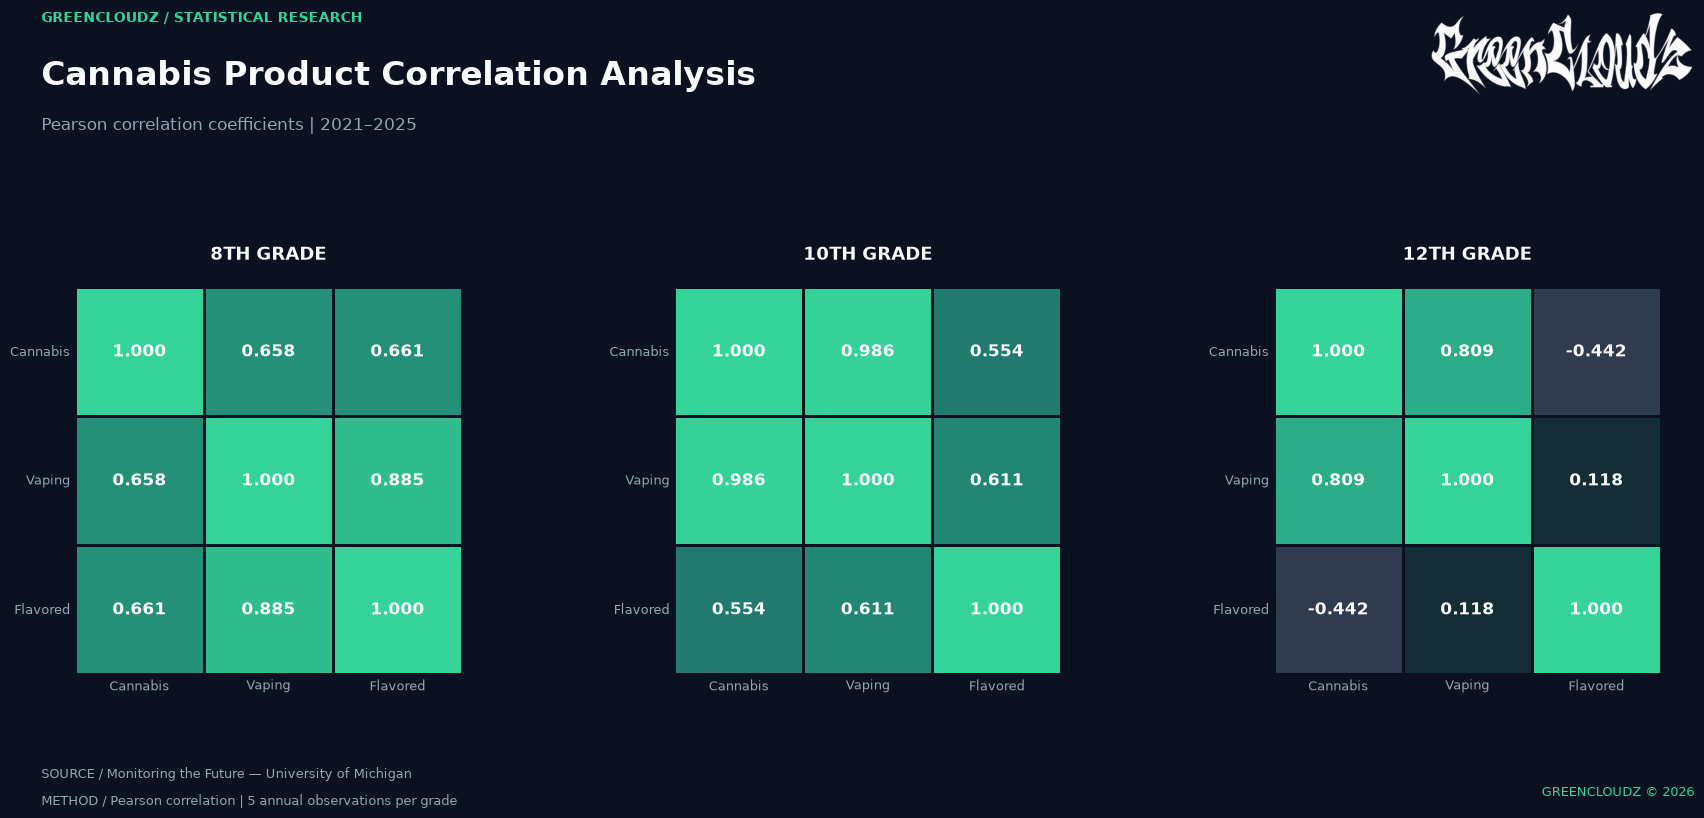

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns

from pathlib import Path
from matplotlib.colors import LinearSegmentedColormap

# --------------------------------------------------
# GREENCLOUDZ | VISUAL IDENTITY
# --------------------------------------------------

COLORS = {
    "background": "#0B1120",
    "panel": "#111827",
    "text": "#F8FAFC",
    "muted": "#94A3B8",
    "grid": "#334155",
    "accent": "#34D399"
}

# Configure typography
available_fonts = {font.name for font in fm.fontManager.ttflist}

font_family = next(
    (
        font for font in ["Montserrat", "Aptos", "DejaVu Sans"]
        if font in available_fonts
    ),
    "DejaVu Sans"
)

plt.rcParams.update({
    "font.family": font_family,
    "font.size": 11,
    "text.color": COLORS["text"],
    "axes.labelcolor": COLORS["muted"],
    "xtick.color": COLORS["muted"],
    "ytick.color": COLORS["muted"]
})

# Define correlation color scale
correlation_cmap = LinearSegmentedColormap.from_list(
    "greencloudz_correlation",
    [
        "#A78BFA",
        "#334155",
        "#111827",
        "#1E6F68",
        "#34D399"
    ]
)

# --------------------------------------------------
# DATA PREPARATION
# --------------------------------------------------

DATA_PATH = Path(
    "../data/processed/cannabis_prevalence_clean.csv"
)

df = pd.read_csv(DATA_PATH)

CATEGORIES = [
    "Cannabis",
    "Vaping Cannabis",
    "Vaping Flavored Cannabis"
]

GRADES = [
    "8th Grade",
    "10th Grade",
    "12th Grade"
]

START_YEAR = 2021
END_YEAR = 2025

correlation_data = df[
    (df["drug"].isin(CATEGORIES))
    & (df["time"] == "12 Month")
    & (df["grade"].isin(GRADES))
    & (df["year"].between(START_YEAR, END_YEAR))
].copy()

# --------------------------------------------------
# FIGURE CONFIGURATION
# --------------------------------------------------

fig, axes = plt.subplots(
    1, 3,
    figsize=(19, 9),
    facecolor=COLORS["background"]
)

fig.subplots_adjust(
    left=0.08,
    right=0.95,
    top=0.65,
    bottom=0.22,
    wspace=0.32
)

# --------------------------------------------------
# HEADER
# --------------------------------------------------

fig.text(
    0.08, 0.945,
    "GREENCLOUDZ / STATISTICAL RESEARCH",
    fontsize=10,
    fontweight="bold",
    color=COLORS["accent"]
)

fig.text(
    0.08, 0.875,
    "Cannabis Product Correlation Analysis",
    fontsize=24,
    fontweight="bold",
    color=COLORS["text"]
)

fig.text(
    0.08, 0.825,
    "Pearson correlation coefficients | 2021–2025",
    fontsize=12,
    color=COLORS["muted"]
)

# --------------------------------------------------
# CORRELATION HEATMAPS
# --------------------------------------------------

for ax, grade in zip(axes, GRADES):

    grade_data = correlation_data[
        correlation_data["grade"] == grade
    ]

    pivot_data = grade_data.pivot(
        index="year",
        columns="drug",
        values="estimate"
    ).reindex(
        index=range(START_YEAR, END_YEAR + 1),
        columns=CATEGORIES
    )

    assert not pivot_data.isna().any().any(), (
        f"Incomplete observations detected for {grade}."
    )

    correlation_matrix = pivot_data.corr(
        method="pearson"
    )

    sns.heatmap(
        correlation_matrix,
        ax=ax,
        cmap=correlation_cmap,
        vmin=-1,
        vmax=1,
        center=0,
        annot=True,
        fmt=".3f",
        annot_kws={
            "fontsize": 12,
            "fontweight": "bold"
        },
        square=True,
        linewidths=2,
        linecolor=COLORS["background"],
        cbar=False
    )

    ax.set_title(
        grade.upper(),
        fontsize=13,
        fontweight="bold",
        color=COLORS["text"],
        pad=20
    )

    ax.set_facecolor(COLORS["panel"])

    ax.set_xlabel("")
    ax.set_ylabel("")

    ax.set_xticklabels(
        ["Cannabis", "Vaping", "Flavored"],
        rotation=0,
        color=COLORS["muted"],
        fontsize=9
    )

    ax.set_yticklabels(
        ["Cannabis", "Vaping", "Flavored"],
        rotation=0,
        color=COLORS["muted"],
        fontsize=9
    )

    ax.tick_params(length=0)

    # Adjust annotation contrast
    for annotation in ax.texts:
        annotation.set_color(COLORS["text"])

# --------------------------------------------------
# GREENCLOUDZ BRANDING
# --------------------------------------------------

logo_path = Path(
    "../assets/branding/greencloudz_white_letters.png"
)

if logo_path.exists():

    logo = plt.imread(logo_path)

    logo_ax = fig.add_axes([
        0.81, 0.86, 0.14, 0.10
    ])

    logo_ax.imshow(logo)
    logo_ax.axis("off")

# --------------------------------------------------
# FOOTER
# --------------------------------------------------

fig.text(
    0.08, 0.105,
    "SOURCE / Monitoring the Future — University of Michigan",
    fontsize=9,
    color=COLORS["muted"]
)

fig.text(
    0.08, 0.075,
    "METHOD / Pearson correlation | 5 annual observations per grade",
    fontsize=9,
    color=COLORS["muted"]
)

fig.text(
    0.95, 0.085,
    "GREENCLOUDZ © 2026",
    fontsize=9,
    color=COLORS["accent"],
    ha="right"
)

# --------------------------------------------------
# EXPORT
# --------------------------------------------------

OUTPUT_PATH = Path("../reports/figures")
OUTPUT_PATH.mkdir(parents=True, exist_ok=True)

fig.savefig(
    OUTPUT_PATH / "cannabis_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()

### 5.4 Year-over-Year Change Correlation Analysis

This section examines whether annual changes in cannabis-related prevalence estimates move in similar directions across product categories.

**Research Question:**

Do changes in general cannabis use, cannabis vaping, and flavored cannabis vaping exhibit similar year-over-year patterns?

**Statistical Approach:**

Pearson correlations are calculated using annual prevalence changes expressed in percentage points.

Unlike correlations calculated from prevalence levels, this approach focuses on changes between consecutive survey years.

**Comparison Parameters:**

- Observation period: 2021–2025.
- Annual changes: 2022–2025.
- Reporting interval: Past 12 months.
- Educational grades: 8th, 10th, and 12th.
- Product categories: Cannabis, Vaping Cannabis, and Vaping Flavored Cannabis.

**Methodological Limitations:**

- Each correlation uses only four annual changes.
- Correlation estimates are highly sensitive to individual observations.
- Differencing does not eliminate all temporal dependencies.
- Correlation does not establish causality or substitution.
- Results are exploratory and should not be interpreted as statistically conclusive.

In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path

# Load the processed dataset
DATA_PATH = Path("../data/processed/cannabis_prevalence_clean.csv")

df = pd.read_csv(DATA_PATH)

# Define comparison parameters
START_YEAR = 2021
END_YEAR = 2025

CATEGORIES = [
    "Cannabis",
    "Vaping Cannabis",
    "Vaping Flavored Cannabis"
]

GRADES = [
    "8th Grade",
    "10th Grade",
    "12th Grade"
]

# Filter comparable observations
analysis_data = df[
    (df["drug"].isin(CATEGORIES))
    & (df["time"] == "12 Month")
    & (df["grade"].isin(GRADES))
    & (df["year"].between(START_YEAR, END_YEAR))
].copy()

# Calculate correlations between annual prevalence changes
yoy_correlations = {}

for grade in GRADES:

    grade_data = analysis_data[
        analysis_data["grade"] == grade
    ]

    # Reshape prevalence observations
    prevalence_matrix = grade_data.pivot(
        index="year",
        columns="drug",
        values="estimate"
    ).reindex(
        index=range(START_YEAR, END_YEAR + 1),
        columns=CATEGORIES
    )

    # Validate data completeness
    assert not prevalence_matrix.isna().any().any(), (
        f"Incomplete observations detected for {grade}."
    )

    # Calculate consecutive annual changes
    annual_changes = prevalence_matrix.diff().dropna()

    # Validate the number of annual changes
    assert len(annual_changes) == 4, (
        f"Unexpected number of annual changes for {grade}."
    )

    # Calculate Pearson correlations
    correlation_matrix = annual_changes.corr(
        method="pearson"
    )

    yoy_correlations[grade] = correlation_matrix

    print(f"\nANNUAL CHANGE CORRELATIONS | {grade.upper()}")
    print("-" * 55)

    display(correlation_matrix.round(3))

    print("ANNUAL PREVALENCE CHANGES (pp)")
    display(annual_changes.round(2))


ANNUAL CHANGE CORRELATIONS | 8TH GRADE
-------------------------------------------------------


drug,Cannabis,Vaping Cannabis,Vaping Flavored Cannabis
drug,,,
Cannabis,1.000,0.562,0.323
Vaping Cannabis,0.562,1.000,0.850
Vaping Flavored Cannabis,0.323,0.850,1.000


ANNUAL PREVALENCE CHANGES (pp)


drug,Cannabis,Vaping Cannabis,Vaping Flavored Cannabis
year,,,
2022,1.2,1.3,0.9
2023,0.0,0.5,1.8
2024,0.8,-0.9,-1.2
2025,-1.5,-0.9,-1.1



ANNUAL CHANGE CORRELATIONS | 10TH GRADE
-------------------------------------------------------


drug,Cannabis,Vaping Cannabis,Vaping Flavored Cannabis
drug,,,
Cannabis,1.000,0.968,0.890
Vaping Cannabis,0.968,1.000,0.895
Vaping Flavored Cannabis,0.890,0.895,1.000


... (3 outputs left out)

drug,Cannabis,Vaping Cannabis,Vaping Flavored Cannabis
drug,,,
Cannabis,1.000,0.644,0.029
Vaping Cannabis,0.644,1.000,0.599
Vaping Flavored Cannabis,0.029,0.599,1.000


ANNUAL PREVALENCE CHANGES (pp)


drug,Cannabis,Vaping Cannabis,Vaping Flavored Cannabis
year,,,
2022,0.2,2.3,1.3
2023,-1.7,-1.0,1.6
2024,-3.2,-2.0,-0.3
2025,-0.1,-1.6,-1.3


: 

### 5.5 Year-over-Year Correlation: Key Findings

**Finding 1 — Strong positive associations among 10th-grade students**

Annual prevalence changes showed positive Pearson correlations across all three cannabis-related categories among 10th-grade students.

The strongest association occurred between general cannabis use and cannabis vaping (r = 0.968).

**Finding 2 — Weak association between general cannabis and flavored vaping among 12th-grade students**

The correlation between annual changes in general cannabis prevalence and flavored cannabis vaping prevalence was approximately zero (r = 0.029).

This contrasts with the negative correlation observed when comparing prevalence levels (r = −0.442).

**Finding 3 — Positive association between vaping categories among 8th-grade students**

Annual changes in cannabis vaping and flavored cannabis vaping exhibited a positive correlation of r = 0.850.

**Interpretation**

Correlations between annual prevalence changes provide an alternative perspective to correlations between prevalence levels.

The results suggest that temporal relationships differ depending on the educational grade and statistical approach.

However, these findings remain exploratory.

**Methodological Limitations**

- Only four annual changes were available per series.
- Correlation coefficients are highly sensitive to individual observations.
- Temporal dependencies may remain after differencing.
- Product categories represent overlapping populations.
- Results do not establish causal relationships or statistical significance.

**Research Conclusion**

Year-over-year correlations are retained as supplementary exploratory findings rather than primary evidence supporting the study's conclusions.